# Chance-constrained programming: a portfolio optimization example

This notebook accompanies the portfolio example of the chance-constrained programming slides.
We maximize the expected return of a portfolio of $n$ assets with random returns $\beta \sim N(\mu, \Sigma)$, while limiting the probability that the return falls below a level $b$:
$$
\max_x\ \mu^T x \quad \text{s.t.} \quad P\left[\beta^T x \geq b\right] \geq 1-\alpha, \quad \sum_{i=1}^n x_i = 1, \quad x \geq -0.1,
$$
where $x_i$ is the proportion of the budget invested in asset $i$, $\alpha$ is the risk level, and the bound $x \geq -0.1$ allows limited short selling: a negative $x_i$ means that the investor sells asset $i$ without owning it, and buys it back at the end of the period.
As $\beta^T x$ is normal, with mean $\mu^T x$ and variance $x^T\Sigma x$, the chance constraint is equivalent to
$$
\mu^T x - z_\alpha \sqrt{x^T \Sigma x} \geq b, \qquad z_\alpha = \Phi^{-1}(1-\alpha),
$$
where $\Phi$ is the distribution function of the standard normal distribution $N(0,1)$: a second-order cone constraint for $\alpha < 0.5$.

**Objectives.** The first part of the notebook illustrates the slides:

1. write the deterministic equivalent of an individual chance constraint with Gaussian returns, and solve the resulting second-order cone program with JuMP;
2. check it by simulation, through the loss probability and the mean loss given a loss;
3. observe that the chance constraint is active at the optimum, and how the risk level $\alpha$ trades expected return for safety;
4. compare with the classical Markowitz model: the chance-constrained model is a Markowitz model whose risk bound is set by $\alpha$ and $b$.

The second part, *Going further*, relates the model to portfolio theory: the Sharpe ratio and the tangency portfolio explain the shape of its solutions, the Markowitz++ formulation of Boyd et al. (2024) shows how weight limits tame it, and the four formulations of the Markowitz model listed in the MOSEK portfolio cookbook give the same efficient portfolios.

**Sources.** S. Boyd and L. Vandenberghe, *Convex Optimization*, Cambridge University Press, 2004: Example 4.8 (Section 4.4.2, pp. 158–159) for the loss risk constraint, and Section 4.7.6 (pp. 186–187) for the data.
The short-selling bound is the one of the numerical illustration of the slides (S. Boyd, EE364a).

In [1]:
using LinearAlgebra, Printf
using JuMP, HiGHS, Clarabel
using Distributions, RandomDataStreams

## Data

Four assets, as in Boyd and Vandenberghe: three risky assets with Gaussian returns, and a risk-free asset, asset 4, with a certain return of 3%.

| Asset | Expected return | Standard deviation |
|:-----:|:---------------:|:------------------:|
| 1     | 12%             | 20%                |
| 2     | 10%             | 10%                |
| 3     | 7%              | 5%                 |
| 4     | 3%              | 0%                 |

The correlations are $\mathrm{corr}(\beta_1, \beta_2) = 0.3$, $\mathrm{corr}(\beta_1, \beta_3) = -0.4$ and $\mathrm{corr}(\beta_2, \beta_3) = 0$, hence the covariances $\Sigma_{ij} = \mathrm{corr}(\beta_i, \beta_j)\, \sigma_i \sigma_j$, with $\sigma_i$ the standard deviation of asset $i$.
The risk-free asset, with a zero variance, is left out of $\Sigma$, which stays positive definite.

In [2]:
n = 4   # number of assets; asset n is risk-free

μ = [0.12, 0.10, 0.07, 0.03]   # expected returns

# Covariance matrix of the risky assets 1, ..., n-1
Σ = [ 4e-2  6e-3 -4e-3;
      6e-3  1e-2  0.0 ;
     -4e-3  0.0   2.5e-3]
Σhalf = sqrt(Σ)   # symmetric square root: x'Σx = ‖Σhalf x‖²

# Joint distribution of the returns of the risky assets
risky = MvNormal(μ[1:n-1], Σ);

## Loss statistics

For a portfolio $x$, the return $\beta^T x$ is normal, with mean $m = \mu^T x$ and standard deviation $s = \sqrt{x^T\Sigma x}$ (the risk-free asset only adds a constant).
With $\Phi$ and $\varphi$ the distribution function and the density of $N(0,1)$, the loss probability is
$$
P\left[\beta^T x < 0\right] = \Phi\left(-\frac{m}{s}\right),
$$
and the mean loss given a loss is
$$
\mathbb{E}\left[-\beta^T x \mid \beta^T x < 0\right] = s\,\frac{\varphi(m/s)}{\Phi(-m/s)} - m.
$$

**Derivation.** Write $\beta^T x = m + sZ$, with $Z \sim N(0,1)$, and $c = -m/s$, so that $\beta^T x < 0$ if and only if $Z < c$.

- The loss probability is $P[Z < c] = \Phi(-m/s)$: this is the standardization of the slide "Example: deterministic equivalent of the chance constraint", with $b = 0$; as the distribution is continuous, $<$ and $\leq$ give the same probability.
- As $\varphi(z) = e^{-z^2/2}/\sqrt{2\pi}$, the chain rule gives $\varphi'(z) = -z\,\varphi(z)$: $-\varphi$ is an antiderivative of $z\,\varphi(z)$, and $\varphi(z) \to 0$ as $z \to -\infty$, so that
  $$
  \mathbb{E}\left[Z\,\mathbb{1}_{\{Z < c\}}\right] = \int_{-\infty}^{c} z\,\varphi(z)\,dz = \Big[-\varphi(z)\Big]_{-\infty}^{c} = -\varphi(c).
  $$
  Dividing by $P[Z < c] = \Phi(c)$ gives the mean of a truncated normal distribution:
  $$
  \mathbb{E}[Z \mid Z < c] = -\frac{\varphi(c)}{\Phi(c)}.
  $$
- Therefore, as $-\beta^T x = -m - sZ$, and by the symmetry $\varphi(-t) = \varphi(t)$,
  $$
  \mathbb{E}\left[-\beta^T x \mid \beta^T x < 0\right] = -m - s\,\mathbb{E}[Z \mid Z < c] = s\,\frac{\varphi(m/s)}{\Phi(-m/s)} - m.
  $$

We also estimate both by simulation, which does not use these formulas, and would apply to any distribution we can sample: it checks the formulas, and the deterministic equivalent.
Every random number comes from a stream of the `RandomDataStreams` library, never from Julia's global generator: `rand(rng, risky)` draws the returns of the risky assets from the stream `rng`.
The stream is rewound at the beginning of each call: every portfolio is evaluated on the same scenarios (common random numbers), so that the differences we observe come from the portfolios themselves, and not from the sampling noise.

In [3]:
# Exact loss probability and mean loss given a loss, for Gaussian returns
function loss_statistics(x)
    m = dot(μ, x)
    s = norm(Σhalf * x[1:n-1])
    ploss = cdf(Normal(), -m/s)
    return ploss, s*pdf(Normal(), m/s)/ploss - m
end

loss_gen = Xoshiro256ppGen(2024)
loss_rng = next_stream!(loss_gen)

# The same statistics, estimated on M scenarios
function simulated_loss_statistics(x; M::Int = 10^6, rng::AbstractStreamableRNG = loss_rng)
    reset_stream!(rng)   # common random numbers: same scenarios for every portfolio
    xr = x[1:n-1]        # risky part of the portfolio
    r0 = x[n]*μ[n]       # return of the risk-free part
    nloss = 0            # number of losses
    total = 0.0          # sum of the losses
    for _ in 1:M
        r = dot(xr, rand(rng, risky)) + r0   # returns drawn from the stream rng
        if r < 0
            nloss += 1
            total -= r
        end
    end
    return nloss/M, total/nloss
end

function report(name, x)
    pe, le = loss_statistics(x)
    ps, ls = simulated_loss_statistics(x)
    println(name)
    @printf("  portfolio:              %s\n", string(round.(x, digits = 4)))
    @printf("  expected return:        %.4f\n", dot(μ, x))
    @printf("  loss probability:       %.4f (simulated: %.4f)\n", pe, ps)
    @printf("  mean loss given a loss: %.4f (simulated: %.4f)\n", le, ls)
end;

## Uniform portfolio

We first consider the naive strategy, which invests the same proportion $1/n$ of the budget in each asset, the risk-free asset included.
We write $x_u$ for this portfolio (`x_uniform` in the code).

In [4]:
x_uniform = fill(1/n, n)
report("Uniform portfolio", x_uniform)

Uniform portfolio


  portfolio:              [0.25, 0.25, 0.25, 0.25]
  expected return:        0.0800


  loss probability:       0.0891 (simulated: 0.0891)
  mean loss given a loss: 0.0275 (simulated: 0.0274)


## Maximum expected return, without loss constraint

We now maximize the expected return, with the budget constraint and the short-selling bound only: a linear program, solved with HiGHS.
We write $x_{lp}$ for its solution.

In [5]:
model = Model(HiGHS.Optimizer)
set_silent(model)

@variable(model, x[1:n] >= -0.1)
@constraint(model, budget, sum(x) == 1)
@objective(model, Max, dot(μ, x))

print(model)
optimize!(model)
termination_status(model)

OPTIMAL::TerminationStatusCode = 1

In [6]:
x_lp = value.(x)
report("Without loss constraint", x_lp)

Without loss constraint


  portfolio:              [1.3, -0.1, -0.1, -0.1]
  expected return:        0.1360
  loss probability:       0.2999 (simulated: 0.2996)
  mean loss given a loss: 0.1645 (simulated: 0.1644)


Not surprisingly, we invest as much as possible in asset 1, which has the highest expected return, and finance it by short selling the three other assets down to the bound $-0.1$.
The loss probability is however close to 30%, and the mean loss given a loss is six times that of the uniform portfolio.

## Maximum expected return, with the loss constraint

We now require a nonnegative return with probability at least 95%: $b = 0$ and $\alpha = 0.05$.
This is an individual chance constraint, with a single inequality inside the probability.
As $z_\alpha > 0$, its deterministic equivalent reads
$$
\lVert \Sigma^{1/2} x_{1:n-1} \rVert_2 \leq \frac{\mu^T x - b}{z_\alpha},
$$
where $\Sigma^{1/2}$ is the symmetric square root of $\Sigma$, so that $x_{1:n-1}^T \Sigma\, x_{1:n-1} = \lVert \Sigma^{1/2} x_{1:n-1} \rVert_2^2$ (only the risky assets contribute to the variance).
The vector $\left( (\mu^T x - b)/z_\alpha,\ \Sigma^{1/2} x_{1:n-1} \right)$ thus belongs to the second-order cone $\lbrace (t, u) : \lVert u \rVert_2 \leq t \rbrace$, `SecondOrderCone()` in JuMP.

In [7]:
b = 0.0    # minimum return: b = 0 means no loss
α = 0.05   # risk level
zα = quantile(Normal(), 1 - α)

1.6448536269514717

HiGHS does not handle second-order cone constraints.
We switch to Clarabel, an open-source interior-point solver for conic programs, and add the constraint to the same model.

In [8]:
set_optimizer(model, Clarabel.Optimizer)
set_silent(model)

@constraint(model, loss_risk, [(dot(μ, x) - b)/zα; Σhalf*x[1:n-1]] in SecondOrderCone())

optimize!(model)
termination_status(model)

OPTIMAL::TerminationStatusCode = 1

In [9]:
x_cc = value.(x)
report("With loss constraint", x_cc)

With loss constraint


  portfolio:              [0.182, 0.3401, 0.5779, -0.1]
  expected return:        0.0933
  loss probability:       0.0500 (simulated: 0.0499)
  mean loss given a loss: 0.0237 (simulated: 0.0237)


As expected, the expected return of the chance-constrained portfolio $x_{cc}$ is lower than without the loss constraint, but still higher than with the uniform portfolio.
The optimal portfolio still sells the risk-free asset short, down to the bound $x_4 = -0.1$.
Holding the risk-free asset ($x_4 > 0$) amounts to **lending** money at its rate, 3%, as when buying a Treasury bill; selling it short ($x_4 < 0$) amounts to **borrowing** at this rate.
The portfolio thus borrows 10% of the budget, to invest 110% of the budget in the risky assets (leverage).
The loss probability is exactly 5%: the chance constraint is active, and the simulation confirms it.
It is the smallest of the three portfolios, and so is the mean loss given a loss.

As the constraint is active, the value-at-risk of the loss at level 95%, that is, the 95% quantile of the loss, is zero: the loss is positive with probability 5%.
The mean loss given a loss, the mean of the loss beyond this quantile, is then the conditional value-at-risk (expected shortfall) of the loss at level 95% (slides "Value at Risk" to "Expected shortfall").

## Effect of the risk level

A smaller risk level $\alpha$ gives a safer portfolio, at the price of a lower expected return.
We solve the problem again for the typical values $\alpha = 0.10, 0.05, 0.01$, replacing the loss risk constraint each time.

In [10]:
# Replace the loss risk constraint by the one of risk level α, and solve again
function solve_with_risk_level!(model, α)
    x = model[:x]
    delete(model, model[:loss_risk])
    unregister(model, :loss_risk)
    zα = quantile(Normal(), 1 - α)
    @constraint(model, loss_risk, [(dot(μ, x) - b)/zα; Σhalf*x[1:n-1]] in SecondOrderCone())
    optimize!(model)
    return value.(x)
end

for a in (0.10, 0.05, 0.01)
    xa = solve_with_risk_level!(model, a)
    @printf("α = %.2f: expected return %.4f, loss probability %.4f, portfolio %s\n",
            a, dot(μ, xa), loss_statistics(xa)[1], string(round.(xa, digits = 3)))
end

α = 0.10: expected return 0.1020, loss probability 0.1000, portfolio [0.238, 0.538, 0.324, -0.1]
α = 0.05: expected return 0.0933, loss probability 0.0500, portfolio [0.182, 0.34, 0.578, -0.1]


α = 0.01: expected return 0.0645, loss probability 0.0100, portfolio [0.083, 0.106, 0.49, 0.321]


The expected return increases with $\alpha$: a safer portfolio costs expected return. The loss probability is always exactly $\alpha$.
For $\alpha = 0.01$, the portfolio no longer borrows: about a third of the budget goes to the risk-free asset.

## Comparison with the Markowitz model

The classical model of Markowitz (1952) bounds the risk directly, through the standard deviation $\sigma(x) = \sqrt{x^T\Sigma x}$ of the return:
$$
\max_x\ \mu^T x \quad \text{s.t.} \quad \sigma(x) \leq \sigma_{\max}, \quad \sum_{i=1}^n x_i = 1, \quad x \geq -0.1,
$$
or, equivalently, minimizes the variance for a target expected return.
As $\sigma_{\max}$ varies, the optimal expected return traces the *efficient frontier* in the plane $(\sigma(x), \mu^T x)$, and the solutions are the *efficient portfolios*: no portfolio has a larger expected return for the same standard deviation, or a smaller standard deviation for the same expected return.
The chance-constrained model bounds instead the probability of a return below $b$, through $\mu^T x - z_\alpha \sigma(x) \geq b$.

In both models, the risk constraint is generally *active*: maximizing the expected return pushes the portfolio toward asset 1, as the linear program above shows, and only the risk constraint holds it back.
It is inactive only if the solution $x_{lp}$ of the linear program above satisfies it, that is, for $\sigma_{\max} \geq \sigma(x_{lp}) \approx 26\%$, or for $\alpha \geq P[\beta^T x_{lp} < 0] \approx 30\%$.

The chance-constrained portfolio $x_{cc}$ also solves the Markowitz model with $\sigma_{\max} = \sigma(x_{cc})$.
Indeed, the solution $x_m$ of this Markowitz model satisfies $\sigma(x_m) \leq \sigma(x_{cc})$, and $\mu^T x_m \geq \mu^T x_{cc}$, as $x_{cc}$ is feasible for it. Hence
$\mu^T x_m - z_\alpha \sigma(x_m) \geq \mu^T x_{cc} - z_\alpha \sigma(x_{cc}) \geq b$:
$x_m$ satisfies the chance constraint, so that $\mu^T x_m \leq \mu^T x_{cc}$.
Both expected returns are thus equal, and $x_{cc}$, feasible for the Markowitz model, is optimal for it.
The chance-constrained model is therefore a Markowitz model, whose risk bound $\sigma_{\max}$ follows from $\alpha$ and $b$ instead of being chosen directly; as both risk constraints are active, it is the standard deviation at which the efficient frontier meets the line $\mu^T x = b + z_\alpha \sigma(x)$.

In [11]:
risk(x) = norm(Σhalf * x[1:n-1])   # standard deviation σ(x) of the return

# Markowitz model: maximum expected return, for a standard deviation at most σmax
function markowitz_model(σmax; risk_free::Bool = true)
    model = Model(Clarabel.Optimizer)
    set_silent(model)
    @variable(model, x[1:n] >= -0.1)
    risk_free || fix(x[n], 0.0; force = true)   # risk_free = false: risky assets only
    @constraint(model, sum(x) == 1)
    @constraint(model, risk_target, [σmax; Σhalf*x[1:n-1]] in SecondOrderCone())
    @objective(model, Max, dot(μ, x))
    optimize!(model)
    return model
end

markowitz(σmax) = value.(markowitz_model(σmax)[:x])   # optimal portfolio

x_m = markowitz(risk(x_cc))
report("Markowitz, σmax = σ(x_cc)", x_m)

Markowitz, σmax = σ(x_cc)


  portfolio:              [0.182, 0.34, 0.578, -0.1]
  expected return:        0.0933
  loss probability:       0.0500 (simulated: 0.0499)
  mean loss given a loss: 0.0237 (simulated: 0.0237)


In [12]:
# Both risk constraints are active (zero up to the solver tolerance)
@printf("Chance-constrained model, α = %.2f: μ'x - zα σ(x) - b = %+.1e\n", α, dot(μ, x_cc) - zα*risk(x_cc) - b)
@printf("Markowitz model:                   σ(x) - σmax       = %+.1e\n", risk(x_m) - risk(x_cc))
@printf("Distance between the two portfolios:                 %.1e\n", norm(x_m - x_cc))
@printf("Linear program: σ(x_lp) = %.4f, loss probability %.4f\n", risk(x_lp), loss_statistics(x_lp)[1])

Chance-constrained model, α = 0.05: μ'x - zα σ(x) - b = +7.9e-10
Markowitz model:                   σ(x) - σmax       = +1.2e-12
Distance between the two portfolios:                 1.1e-04
Linear program: σ(x_lp) = 0.2592, loss probability 0.2999


# Going further: portfolio theory

The next sections relate the chance-constrained model to the theory of portfolio selection.
They are not needed to understand the chance constraint, but they explain the shape of its solutions.

## Sharpe ratios

The Sharpe ratio (Sharpe, 1966) is the expected return in excess of the risk-free rate $r_f$, here the 3% of asset 4, per unit of standard deviation:
$$
S(x) = \frac{\mu^T x - r_f}{\sigma(x)}.
$$
**Largest Sharpe ratio.** Let $w = x_{1:n-1}$ be the risky part of a portfolio $x$, and $v = \mu_{1:n-1} - r_f \mathbf{1}$ the expected excess returns of the risky assets, where $\mathbf{1}$ is the vector of ones.
As $x_n = 1 - \mathbf{1}^T w$, the excess return is $\mu^T x - r_f = v^T w$, for any portfolio.
By the Cauchy-Schwarz inequality, as in the short selling case of the slides,
$$
v^T w = \left(\Sigma^{-1/2} v\right)^T \left(\Sigma^{1/2} w\right) \leq \lVert \Sigma^{-1/2} v \rVert_2\, \lVert \Sigma^{1/2} w \rVert_2,
$$
where $\lVert \Sigma^{-1/2} v \rVert_2 = \sqrt{v^T \Sigma^{-1} v}$, and $\lVert \Sigma^{1/2} w \rVert_2 = \sqrt{w^T \Sigma w} = \sigma(x)$, as the risk-free asset does not contribute to the variance.
Hence
$$
\mu^T x - r_f \leq \sqrt{v^T \Sigma^{-1} v}\ \sigma(x),
$$
with equality if and only if $w$ is a nonnegative multiple of $\Sigma^{-1} v$.
Every portfolio thus has a Sharpe ratio at most $S^* = \sqrt{v^T \Sigma^{-1} v}$, reached exactly when its risky part is proportional to $\Sigma^{-1} v$.

**Tangency portfolio.** The bound leaves one degree of freedom: every portfolio whose risky part $w$ is a positive multiple of $\Sigma^{-1} v$ reaches $S^*$, whatever the multiple.
These portfolios hold the risky assets in the same proportions; they differ only by the share of the budget invested in them, the rest being invested at the risk-free rate.

Among them, a single one invests nothing in the risk-free asset: its risky weights sum to 1, which fixes the multiple.
It is the *tangency portfolio*
$$
x_t = \left( \frac{\Sigma^{-1} v}{\mathbf{1}^T \Sigma^{-1} v},\ 0 \right).
$$
The multiple $1/\mathbf{1}^T \Sigma^{-1} v$ must be positive, and it is here ($\mathbf{1}^T \Sigma^{-1} v = 30.47$).
We obtain $x_t = (0.12, 0.16, 0.72, 0)$, with an expected return of 8.1% and a standard deviation of 4.1%.

**All the other portfolios of Sharpe ratio $S^*$ mix $x_t$ and the risk-free asset.**
With $e_n$ the portfolio invested in the risk-free asset only, they are
$$
x = \theta\, x_t + (1-\theta)\, e_n, \qquad \theta \geq 0:
$$
the fraction $\theta$ of the budget goes to $x_t$, and the rest is lent at the rate $r_f$; if $\theta > 1$, the investor borrows at the rate $r_f$ to invest more than the budget in $x_t$.
The risky part of $x$ is $\theta$ times that of $x_t$, so its standard deviation and its excess return are both multiplied by $\theta$:
$$
\sigma(x) = \theta\, \sigma(x_t), \qquad \mu^T x - r_f = \theta\, (\mu^T x_t - r_f),
$$
and its Sharpe ratio is still $S^*$.

**Why "tangency".** In the plane $(\sigma(x), \mu^T x)$ of the figure below, these mixes form a half-line that starts at the risk-free asset $(0, r_f)$, with slope $S^*$: the *capital market line*
$$
\mu^T x = r_f + S^* \sigma(x).
$$
As no portfolio has a Sharpe ratio above $S^*$, no portfolio lies above this line.
Consider now the frontier of the portfolios of risky assets only (dash-dotted curve): $x_t$ is both on this curve and on the line, and the curve never goes above the line.
The line thus touches the curve at $x_t$ without crossing it: it is tangent to the curve at $x_t$.
Put differently, of all the lines from the risk-free asset to a portfolio of risky assets only, the line to $x_t$ is the steepest.

**Consequence: two-fund separation (Tobin, 1958).** Without bounds on $x$, the efficient portfolios of the Markowitz model are exactly the points of the capital market line.
Whatever the risk level $\sigma_{\max}$, the investor holds the same risky portfolio $x_t$, and only the share $\theta = \sigma_{\max}/\sigma(x_t)$ changes: a cautious investor lends at the risk-free rate ($\theta < 1$), a bold one borrows ($\theta > 1$).
Our bounds $x \geq -0.1$ limit the borrowing: $x_t$ satisfies them, and so does the mix as long as $x_4 = 1 - \theta \geq -0.1$, that is $\theta \leq 1.1$, or $\sigma(x) \leq 4.5\%$.
To take more risk, the investor can no longer borrow, and has to change the proportions of the risky assets: the efficient frontier leaves the line at this kink ($\sigma = 4.5\%$, $\mu^T x = 8.6\%$), and the Sharpe ratio decreases.

With $b = 0$, the chance constraint reads $\mu^T x / \sigma(x) \geq z_\alpha$: a bound on the same kind of ratio, measured against a zero return instead of $r_f$, as in the safety-first criterion of Roy (1952).
With $b = r_f$, it would be exactly $S(x) \geq z_\alpha$.

In [13]:
rf = μ[n]   # risk-free rate
sharpe(x) = (dot(μ, x) - rf)/risk(x)

# Tangency portfolio: risky part proportional to Σ⁻¹v, with v = μ - rf, nothing in the risk-free asset
v = μ[1:n-1] .- rf
u = Σ \ v   # direction Σ⁻¹v of the risky part
x_t = [u ./ sum(u); 0.0]
@printf("Tangency portfolio: %s, Sharpe ratio %.4f, and S* = sqrt(v'Σ⁻¹v) = %.4f\n\n",
        string(round.(x_t, digits = 4)), sharpe(x_t), sqrt(dot(v, Σ \ v)))

portfolios = [("Uniform", x_uniform), ("Without loss constraint", x_lp)]
for a in (0.10, 0.05, 0.01)
    push!(portfolios, (@sprintf("Chance-constrained, α = %.2f", a), solve_with_risk_level!(model, a)))
end
push!(portfolios, ("Tangency", x_t))

leverage(x) = norm(x[1:n-1], 1)   # gross leverage of the risky assets

@printf("%-30s %8s %8s %10s %8s %9s %8s\n", "portfolio", "μ'x", "σ(x)", "μ'x/σ(x)", "x_4", "leverage", "S(x)")
for (name, x) in portfolios
    @printf("%-30s %8.4f %8.4f %10.4f %8.4f %9.4f %8.4f\n",
            name, dot(μ, x), risk(x), dot(μ, x)/risk(x), x[n], leverage(x), sharpe(x))
end

Tangency portfolio: [0.1225, 0.1562, 0.7212, 0.0], Sharpe ratio 1.2442, and S* = sqrt(v'Σ⁻¹v) = 1.2442

portfolio                           μ'x     σ(x)   μ'x/σ(x)      x_4  leverage     S(x)


Uniform                          0.0800   0.0594     1.3463   0.2500    0.7500   0.8414
Without loss constraint          0.1360   0.2592     0.5246  -0.1000    1.5000   0.4089


Chance-constrained, α = 0.10     0.1020   0.0796     1.2816  -0.1000    1.1000   0.9047
Chance-constrained, α = 0.05     0.0933   0.0567     1.6449  -0.1000    1.1000   1.1160
Chance-constrained, α = 0.01     0.0645   0.0277     2.3263   0.3212    0.6788   1.2442
Tangency                         0.0808   0.0408     1.9788   0.0000    1.0000   1.2442


The chance-constrained portfolios satisfy $\mu^T x / \sigma(x) = z_\alpha$ exactly ($z_{0.10} = 1.28$, $z_{0.05} = 1.64$, $z_{0.01} = 2.33$): the constraint is active.

Their Sharpe ratios increase as $\alpha$ decreases.
For $\alpha = 0.01$, the portfolio lends at the risk-free rate ($x_4 > 0$): it lies on the capital market line, and its Sharpe ratio is the largest possible, that of the tangency portfolio.
For $\alpha = 0.05$ and $0.10$, the portfolio borrows up to the bound $x_4 = -0.1$, and its Sharpe ratio is lower: a higher expected return is bought at the price of a lower return per unit of risk.
Both naive strategies have lower Sharpe ratios: the uniform portfolio, because it is not efficient, and the portfolio without loss constraint, because of its standard deviation of about 26%.

The figure shows the efficient frontier of the Markowitz model, which follows the capital market line until the borrowing bound is reached, and the frontier of the portfolios of risky assets only, to which the capital market line is tangent at the tangency portfolio.
It also shows the boundary $\mu^T x = b + z_\alpha \sigma(x)$ of the chance constraint for $\alpha = 0.05$: the chance-constrained portfolio is where this boundary meets the efficient frontier, so the constraint is active.

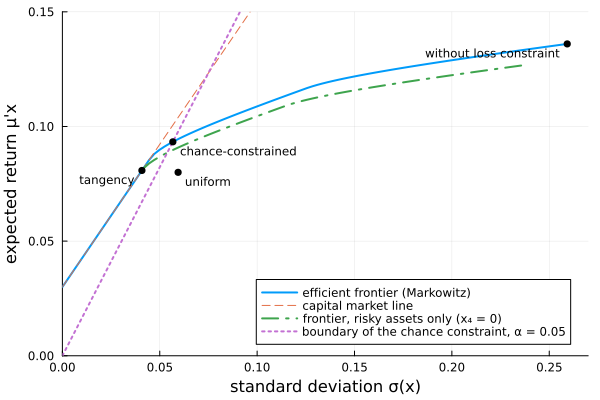

In [14]:
using Plots

σs = range(0.0, risk(x_lp), length = 100)
frontier = [markowitz(s) for s in σs]

fig = plot(risk.(frontier), [dot(μ, x) for x in frontier], label = "efficient frontier (Markowitz)",
           xlabel = "standard deviation σ(x)", ylabel = "expected return μ'x",
           legend = :bottomright, xlims = (0, 0.27), ylims = (0, 0.15), linewidth = 2)
plot!(fig, σs, rf .+ sharpe(x_t) .* σs, label = "capital market line", linestyle = :dash)

# Frontier of the portfolios of risky assets only (x₄ = 0), where it exists
risky_models = [markowitz_model(s; risk_free = false) for s in σs]
risky_only = [value.(m[:x]) for m in risky_models if termination_status(m) == MOI.OPTIMAL]
plot!(fig, risk.(risky_only), [dot(μ, x) for x in risky_only], label = "frontier, risky assets only (x₄ = 0)",
      linestyle = :dashdot, linewidth = 2)
plot!(fig, σs, b .+ zα .* σs, label = "boundary of the chance constraint, α = 0.05", linestyle = :dot, linewidth = 2)

points = [(x_uniform, "uniform", :left, 0.004), (x_lp, "without loss constraint", :right, -0.004),
          (x_cc, "chance-constrained", :left, 0.004), (x_t, "tangency", :right, -0.004)]
for (x, label, align, dx) in points
    scatter!(fig, [risk(x)], [dot(μ, x)], label = "", color = :black, markersize = 4)
    annotate!(fig, risk(x) + dx, dot(μ, x) - 0.004, text(label, align, 8))
end
display("image/png", fig)   # stored once, as an image

## Link with Markowitz++ (Boyd et al., 2024)

In *Markowitz portfolio construction at seventy* ([arXiv:2401.05080](https://arxiv.org/abs/2401.05080), *Journal of Portfolio Management*, 2024), S. Boyd, K. Johansson, R. Kahn, P. Schiele and T. Schmelzer revisit the Markowitz model, seventy years after it was proposed.
The models of this notebook are small instances of theirs:

| This notebook | Boyd et al. (2024) |
|:--|:--|
| Markowitz model, $\max \mu^T x$ s.t. $\sigma(x) \leq \sigma_{\max}$, $\sum_i x_i = 1$ | basic Markowitz problem (1), with the risk target $\sigma^{\rm tar}$ |
| risky assets $x_{1:n-1}$, risk-free asset $x_n$ with return $r_f$ | asset weights $w$, cash weight $c$ with return $r_{\rm rf}$, and $\mathbf{1}^T w + c = 1$ |
| bounds $x_{1:n-1} \geq -0.1$ | weight limits $w \geq w^{\min}$ |
| bound $x_n \geq -0.1$ | cash limit $c \geq c^{\min}$, i.e., limited borrowing |
| $\lVert x_{1:n-1} \rVert_1$ | gross leverage $L = \lVert w \rVert_1$ |
| ex-ante Sharpe ratios, with $\mu$ and $\Sigma$ assumed exact | realized (ex-post) Sharpe ratios of back-tests, with forecasts of $\mu$ and $\Sigma$ |

A *back-test* simulates the strategy on past data: each day, the problem is solved with the forecasts available that day, the portfolio is rebalanced, and its realized returns are recorded.


- **Risk target.** They recommend maximizing the expected return under a risk target, as here, rather than the risk-adjusted return $\mu^T w - \gamma w^T \Sigma w$, because $\sigma^{\rm tar}$ is interpretable.
The parameters $\alpha$ and $b$ of the chance-constrained model are interpretable too, and, as shown above, they set the risk target of an equivalent Markowitz model.
- **Risk symmetry.** One of the criticisms they discuss is that the variance penalizes gains as much as losses.
The chance constraint only looks at the lower tail, but with Gaussian returns it reduces to a constraint on the mean and the standard deviation: it differs from the Markowitz model only for non-Gaussian returns, for instance when the returns are described by scenarios.
The CVaR constraint of the slides also looks only at the lower tail.
- **Taming Markowitz.** Their back-tests show that the basic Markowitz problem, sensitive to forecast errors, takes extreme positions and performs poorly: Sharpe ratio 0.19 and leverage 9.3, worse than the equal-weight portfolio (0.66).
A single reasonable constraint tames it: weight limits raise the Sharpe ratio to 1.69, a leverage limit to 1.86.
With all these constraints, robust forecasts, transaction costs and soft constraints (Markowitz++), it reaches 4.32.
As the authors stress, these values only compare the methods: the universe keeps the stocks of the S&P 100 that have data over the whole period, hence the stocks that survived (survivorship bias), and the return forecasts are synthetic, obtained by adding noise to the realized returns.

Our bounds $x \geq -0.1$ are such weight and cash limits. The next cell removes them from the chance-constrained model.

In [15]:
# Chance-constrained model without the weight and cash limits x ≥ -0.1
function chance_constrained_unbounded_weights(α)
    model = Model(Clarabel.Optimizer)
    set_silent(model)
    @variable(model, x[1:n])
    @constraint(model, sum(x) == 1)
    zα = quantile(Normal(), 1 - α)
    @constraint(model, [(dot(μ, x) - b)/zα; Σhalf*x[1:n-1]] in SecondOrderCone())
    @objective(model, Max, dot(μ, x))
    optimize!(model)
    status = termination_status(model)
    return status, status == MOI.OPTIMAL ? value.(x) : nothing
end

S_star = sharpe(x_t)
@printf("Maximum Sharpe ratio S* = %.4f; unbounded problem for α ≥ 1 - Φ(S*) = %.4f\n\n", S_star, cdf(Normal(), -S_star))
for a in (0.20, 0.10, 0.05, 0.01)
    status, x = chance_constrained_unbounded_weights(a)
    if x === nothing
        @printf("α = %.2f: %s (unbounded)\n", a, status)
    else
        @printf("α = %.2f: expected return %.4f, σ(x) = %.4f, leverage %5.2f, x_4 = %6.2f, Sharpe ratio %.4f\n",
                a, dot(μ, x), risk(x), leverage(x), x[n], sharpe(x))
    end
end

Maximum Sharpe ratio S* = 1.2442; unbounded problem for α ≥ 1 - Φ(S*) = 0.1067

α = 0.20: DUAL_INFEASIBLE (unbounded)


α = 0.10: expected return 1.0304, σ(x) = 0.8040, leverage 19.69, x_4 = -18.69, Sharpe ratio 1.2442
α = 0.05: expected return 0.1232, σ(x) = 0.0749, leverage  1.83, x_4 =  -0.83, Sharpe ratio 1.2442


α = 0.01: expected return 0.0645, σ(x) = 0.0277, leverage  0.68, x_4 =   0.32, Sharpe ratio 1.2442


Without the limits, all the chance-constrained portfolios lie on the capital market line, $\mu^T x = r_f + S^* \sigma(x)$, and have the maximal Sharpe ratio.
With $b = 0$, the chance constraint then reads $r_f \geq (z_\alpha - S^*)\, \sigma(x)$: it bounds the risk only if $z_\alpha > S^*$, that is, $\alpha < 1 - \Phi(S^*) \approx 10.7\%$.
This is the condition $\rho < z_\alpha$ of the slide "Short selling case: no risk-free asset", where $\rho = \sqrt{\mu^T \Sigma^{-1} \mu}$ is the largest ratio $\mu^T x / \sigma(x)$ without a risk-free asset; with a risk-free asset, the maximal Sharpe ratio $S^*$ plays its role.
For $\alpha = 0.10$, just below the threshold, the portfolio borrows almost 19 times its value, for an expected return above 100% and a standard deviation of 80%; for $\alpha = 0.20$, nothing stops the borrowing.

So the chance constraint alone does not tame the model: its risk bound, $z_\alpha$ standard deviations below the mean, can be met by scaling up the most efficient portfolio.
The weight and cash limits do, as in Boyd et al.
In the model, these leveraged portfolios have the best possible Sharpe ratio; with forecast errors on $\mu$, they would amplify them, which is the sensitivity the paper addresses.

**Beyond this notebook.** Markowitz++ adds further ingredients to the basic problem: holding and transaction costs, trading constraints, robust forecasts, soft constraints, and the tuning of their parameters by back-testing.
They address the use of the model in practice, where the problem is solved again at each period with revised forecasts.
We do not implement them: this notebook compares formulations whose parameters $\mu$ and $\Sigma$ are known exactly.
Two of them would nevertheless apply directly to the chance-constrained model, which would remain a second-order cone program.

- **Robust return forecasts** (their Section 3.5). If each $\mu_i$ of a risky asset is only known to lie in $[\mu_i - \varepsilon_i, \mu_i + \varepsilon_i]$ (they write $\rho_i$), the worst-case expected return is $\mu^T x - \varepsilon^T |x_{1:n-1}|$.
Requiring the chance constraint for every mean in these ranges gives
$$
\mu^T x - \varepsilon^T |x_{1:n-1}| - z_\alpha\, \sigma(x) \geq b,
$$
still a second-order cone constraint once $|x_{1:n-1}|$ is replaced by auxiliary variables $t \geq x_{1:n-1}$, $t \geq -x_{1:n-1}$.
The penalty $\varepsilon^T |x_{1:n-1}|$ grows with the positions, and thus discourages the leveraged portfolios above.
- **Soft constraints** (their Section 4.2). A hard limit such as $\sigma(x) \leq \sigma^{\rm tar}$ may make the problem infeasible, or force large trades; they replace it by the penalty $\gamma^{\rm risk} (\sigma(x) - \sigma^{\rm tar})_+$ in the objective, which allows small violations.
The chance constraint could be softened in the same way, by penalizing the amount $\left(b - \mu^T x + z_\alpha\, \sigma(x)\right)_+$ by which the quantile falls below $b$.
To choose the priority $\gamma^{\rm risk}$, they solve the problem with the hard constraint over a back-test, record its Lagrange multipliers, and take a quantile of them, for instance the 80th percentile, so that the constraint holds roughly 80% of the time.

**The multiplier of the risk constraint.** This last rule rests on a property that we can check here.
As the risk constraint is generally active, its Lagrange multiplier is positive: it is the expected return gained per unit of additional risk target, that is, the slope of the efficient frontier at $\sigma_{\max}$.
With a priority larger than this slope, exceeding the target costs more than it brings, and the optimizer respects the target; with a smaller priority, it exceeds it.
The next cell computes the multiplier of the risk target of the Markowitz model equivalent to each chance-constrained portfolio, and compares it with the slope of the frontier, computed by finite differences.

In [16]:
# Multiplier of the risk target, and slope of the efficient frontier (central difference)
h = 1e-4
for (name, x) in portfolios[3:5]   # the three chance-constrained portfolios
    σx = risk(x)
    multiplier = dual(markowitz_model(σx)[:risk_target])[1]
    slope = (dot(μ, markowitz(σx + h)) - dot(μ, markowitz(σx - h)))/(2h)
    @printf("%-30s σmax = %.4f: multiplier %.4f, slope of the frontier %.4f\n", name, σx, multiplier, slope)
end

Chance-constrained, α = 0.10   σmax = 0.0796: multiplier 0.3437, slope of the frontier 0.3437
Chance-constrained, α = 0.05   σmax = 0.0567: multiplier 0.4507, slope of the frontier 0.4507


Chance-constrained, α = 0.01   σmax = 0.0277: multiplier 1.2442, slope of the frontier 1.2442


On the capital market line ($\alpha = 0.01$), the multiplier is the maximal Sharpe ratio $S^*$; beyond the kink of the frontier, each additional unit of risk buys less expected return, and the multiplier decreases.

## Formulations of the Markowitz model (MOSEK cookbook)

The [MOSEK Portfolio Optimization Cookbook](https://docs.mosek.com/portfolio-cookbook/markowitz.html) (Section 2.1) lists four formulations of the mean–variance model, written here with our budget constraint and bounds:

- (2.1) minimize $x^T \Sigma x$ s.t. $\mu^T x \geq r_{\min}$: minimum variance for a target expected return;
- (2.2) maximize $\mu^T x$ s.t. $x^T \Sigma x \leq \gamma^2$: maximum expected return for a risk limit, the Markowitz model above;
- (2.3) maximize $\mu^T x - \frac{\delta}{2} x^T \Sigma x$: quadratic utility, with risk aversion $\delta$;
- (2.4) maximize $\mu^T x - \tilde{\delta} \sqrt{x^T \Sigma x}$: expected return minus $\tilde{\delta}$ standard deviations.

As their parameters vary, they give the same efficient portfolios.
Their optimality conditions differ only by the coefficient of the gradient $\Sigma x$ of the risk term: $\lambda/\sigma(x)$ in (2.2), where $\lambda$ is the multiplier of the risk constraint $\sigma(x) \leq \gamma$, that is, the slope of the efficient frontier; $\delta$ in (2.3); $\tilde{\delta}/\sigma(x)$ in (2.4).
A solution $x^*$ of (2.2) therefore also solves (2.1) with $r_{\min} = \mu^T x^*$, (2.3) with $\delta = \lambda/\sigma(x^*)$, and (2.4) with $\tilde{\delta} = \lambda$.
The next cell checks it at the chance-constrained portfolio for $\alpha = 0.05$.

In [17]:
function base_model()
    model = Model(Clarabel.Optimizer)
    set_silent(model)
    @variable(model, x[1:n] >= -0.1)
    @constraint(model, sum(x) == 1)
    return model, x
end

# (2.1) minimum variance, for an expected return at least rmin
function min_variance(rmin)
    model, x = base_model()
    @constraint(model, dot(μ, x) >= rmin)
    @objective(model, Min, x[1:n-1]' * Σ * x[1:n-1])
    optimize!(model)
    return value.(x)
end

# (2.2) maximum expected return, for a standard deviation at most γ: markowitz(γ) above

# (2.3) maximum quadratic utility, risk aversion δ
function max_utility(δ)
    model, x = base_model()
    @objective(model, Max, dot(μ, x) - δ/2 * x[1:n-1]' * Σ * x[1:n-1])
    optimize!(model)
    return value.(x)
end

# (2.4) maximum expected return minus δ̃ standard deviations
function max_mean_minus_std(δ̃)
    model, x = base_model()
    @variable(model, s)
    @constraint(model, [s; Σhalf*x[1:n-1]] in SecondOrderCone())
    @objective(model, Max, dot(μ, x) - δ̃*s)
    optimize!(model)
    return value.(x)
end

# Matched parameters at the chance-constrained portfolio, α = 0.05
σc = risk(x_cc)
λc = dual(markowitz_model(σc)[:risk_target])[1]   # slope of the frontier at x_cc
matched = [(@sprintf("(2.1) rmin = μ'x_cc = %.4f", dot(μ, x_cc)), min_variance(dot(μ, x_cc))),
           (@sprintf("(2.2) γ = σ(x_cc) = %.4f", σc), markowitz(σc)),
           (@sprintf("(2.3) δ = λ/σ(x_cc) = %.3f", λc/σc), max_utility(λc/σc)),
           (@sprintf("(2.4) δ̃ = λ = %.4f", λc), max_mean_minus_std(λc))]
for (name, x) in matched
    @printf("%-32s μ'x = %.4f  σ(x) = %.4f  S(x) = %.4f  distance to x_cc: %.1e\n",
            name, dot(μ, x), risk(x), sharpe(x), norm(x - x_cc))
end

(2.1) rmin = μ'x_cc = 0.0933     μ'x = 0.0933  σ(x) = 0.0567  S(x) = 1.1160  distance to x_cc: 1.2e-04
(2.2) γ = σ(x_cc) = 0.0567       μ'x = 0.0933  σ(x) = 0.0567  S(x) = 1.1160  distance to x_cc: 1.1e-04


(2.3) δ = λ/σ(x_cc) = 7.945      μ'x = 0.0933  σ(x) = 0.0567  S(x) = 1.1159  distance to x_cc: 9.1e-05
(2.4) δ̃ = λ = 0.4507             μ'x = 0.0933  σ(x) = 0.0567  S(x) = 1.1159  distance to x_cc: 9.7e-05


The four formulations give the same portfolio, up to the solver tolerance, hence the same Sharpe ratio.
The Sharpe ratio is a property of a point of the efficient frontier, not of the formulation that leads to it.
The next cell traces the frontier with (2.1), (2.2) and (2.3), for a range of their parameters.

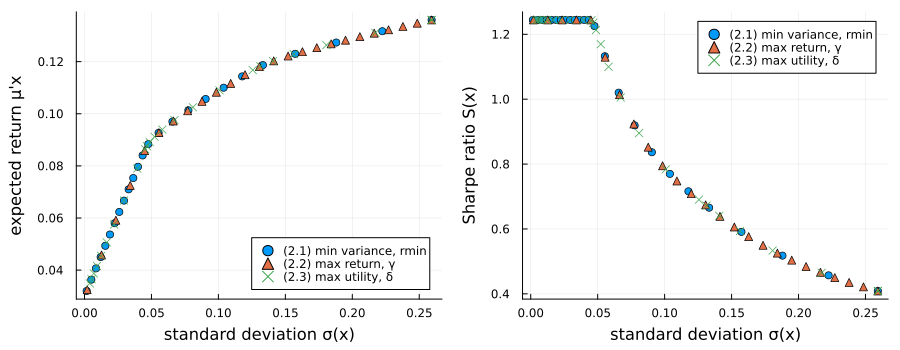

In [18]:
r_grid = range(rf + 0.002, dot(μ, x_lp), length = 25)   # (2.1): rmin above the risk-free return
γ_grid = range(0.002, risk(x_lp), length = 25)          # (2.2)
δ_grid = 10 .^ range(-0.5, 2.5, length = 25)            # (2.3)

sweeps = [("(2.1) min variance, rmin", min_variance.(r_grid), :circle),
          ("(2.2) max return, γ", markowitz.(γ_grid), :utriangle),
          ("(2.3) max utility, δ", max_utility.(δ_grid), :xcross)]

fig2 = plot(layout = (1, 2), size = (900, 350), legend = :bottomright, left_margin = 5Plots.mm, bottom_margin = 5Plots.mm)
for (label, xs, shape) in sweeps
    scatter!(fig2[1], risk.(xs), [dot(μ, x) for x in xs], label = label, markershape = shape, markersize = 4)
    scatter!(fig2[2], risk.(xs), sharpe.(xs), label = label, markershape = shape, markersize = 4)
end
plot!(fig2[1], xlabel = "standard deviation σ(x)", ylabel = "expected return μ'x")
plot!(fig2[2], xlabel = "standard deviation σ(x)", ylabel = "Sharpe ratio S(x)", legend = :topright)
display("image/png", fig2)

The three formulations trace the same frontier, with the same Sharpe ratio for a given risk: $S^* = 1.244$ on the capital market line, up to the borrowing bound ($\sigma(x) \leq 4.5\%$, $\mu^T x \leq 8.6\%$), then a decreasing Sharpe ratio.
Each of them reaches the maximal Sharpe ratio: (2.1) for $r_f < r_{\min} \leq 8.6\%$, (2.2) for $\gamma \leq 4.5\%$, (2.3) for $\delta \geq S^*/4.5\% \approx 28$.

**Formulation (2.1).** Its return constraint is active as soon as $r_{\min}$ exceeds the return of the minimum-variance portfolio, here the risk-free asset and its 3%: the portfolio then returns exactly $r_{\min}$, never more.
This does not make (2.1) less efficient: its solution lies on the frontier, and (2.2) with $\gamma$ equal to its standard deviation gives the same portfolio.
But the return is fixed in advance, instead of following from a risk budget, and nothing in the solution shows how much more return a little more risk would buy, unless we look at the multiplier of the return constraint, or trace the frontier.

In [19]:
for rmin in (0.05, 0.08, 0.10, 0.12)
    x = min_variance(rmin)
    @printf("(2.1) rmin = %.2f: μ'x = %.4f, σ(x) = %.4f, S(x) = %.4f, risk-free asset x_4 = %6.3f\n",
            rmin, dot(μ, x), risk(x), sharpe(x), x[n])
end

(2.1) rmin = 0.05: μ'x = 0.0500, σ(x) = 0.0161, S(x) = 1.2442, risk-free asset x_4 =  0.606
(2.1) rmin = 0.08: μ'x = 0.0800, σ(x) = 0.0402, S(x) = 1.2442, risk-free asset x_4 =  0.016


(2.1) rmin = 0.10: μ'x = 0.1000, σ(x) = 0.0738, S(x) = 0.9484, risk-free asset x_4 = -0.100
(2.1) rmin = 0.12: μ'x = 0.1200, σ(x) = 0.1397, S(x) = 0.6441, risk-free asset x_4 = -0.100


A cautious target, $r_{\min} = 5\%$, gives the maximal Sharpe ratio, but leaves 60% of the budget in the risk-free asset, with a standard deviation of 1.6%: the return is limited by the target, not by the risk.

**Formulation (2.4) and the chance constraint.**
With $\tilde{\delta} = z_\alpha$, (2.4) maximizes the $\alpha$-quantile $\mu^T x - z_\alpha \sigma(x)$ of the return, which the cookbook relates to the value-at-risk; the chance-constrained model instead maximizes the expected return while bounding this quantile, $\mu^T x - z_\alpha \sigma(x) \geq b$.
With a risk-free asset, (2.4) behaves differently from the three other formulations.
On the capital market line, its objective $r_f + (S^* - \tilde{\delta})\,\sigma(x)$ is linear in the risk: for $\tilde{\delta} > S^*$, the optimum is the risk-free asset alone, with a zero standard deviation; for $\tilde{\delta} = S^*$, any portfolio of the line is optimal; for $\tilde{\delta} < S^*$, the optimum lies at the kink or beyond.
(2.4) thus reaches $S^*$ at the kink, but cannot select a lower risk on the capital market line: the portfolios that lend at the risk-free rate ($0 < \theta < 1$) are optimal only for $\tilde{\delta} = S^*$, together with the whole line, and the solver then returns any of them.
In particular, minimizing the value-at-risk at level 95% ($\tilde{\delta} = z_{0.05} = 1.645 > S^*$) puts the whole budget in the risk-free asset.

In [20]:
for δ̃ in (0.5, 1.0, 1.2, 1.3, quantile(Normal(), 0.95))
    x = max_mean_minus_std(δ̃)
    @printf("(2.4) δ̃ = %.3f: μ'x = %.4f, σ(x) = %.4f, portfolio %s\n", δ̃, dot(μ, x), risk(x), string(round.(x, digits = 3)))
end

(2.4) δ̃ = 0.500: μ'x = 0.0917, σ(x) = 0.0534, portfolio [0.172, 0.304, 0.624, -0.1]
(2.4) δ̃ = 1.000: μ'x = 0.0867, σ(x) = 0.0456, portfolio [0.14, 0.19, 0.77, -0.1]
(2.4) δ̃ = 1.200: μ'x = 0.0860, σ(x) = 0.0450, portfolio [0.136, 0.175, 0.79, -0.1]
(2.4) δ̃ = 1.300: μ'x = 0.0300, σ(x) = 0.0000, portfolio [0.0, 0.0, 0.0, 1.0]
(2.4) δ̃ = 1.645: μ'x = 0.0300, σ(x) = 0.0000, portfolio [0.0, 0.0, 0.0, 1.0]


## Summary

- With Gaussian returns, the individual chance constraint $P[\beta^T x \geq b] \geq 1 - \alpha$ is equivalent to $\mu^T x - z_\alpha \sigma(x) \geq b$, a second-order cone constraint for $\alpha < 0.5$; the simulation confirms the loss probability and the mean loss given a loss.
- The chance constraint is active at the optimum: the loss probability is exactly $\alpha$, and a lower risk level costs expected return (10.2%, 9.3% and 6.5% for $\alpha = 0.10$, $0.05$ and $0.01$).
- The chance-constrained portfolio is a Markowitz portfolio, whose risk bound $\sigma_{\max}$ is set by $\alpha$ and $b$ rather than chosen directly.
- With a risk-free asset, the efficient portfolios mix the risk-free asset and the tangency portfolio, up to the borrowing limit. The chance constraint alone does not prevent extreme borrowing: without the weight and cash limits, the portfolio borrows 19 times the budget for $\alpha = 0.10$, and the problem is unbounded for $\alpha \geq 10.7\%$.
- The formulations of the Markowitz model give the same efficient portfolios, hence the same Sharpe ratios; they differ by what is fixed in advance: a return target, a risk limit, or a risk aversion.

## References

- H. Markowitz, "Portfolio selection", *The Journal of Finance* 7(1), 77–91, 1952.
- A. D. Roy, "Safety first and the holding of assets", *Econometrica* 20(3), 431–449, 1952.
- J. Tobin, "Liquidity preference as behavior towards risk", *The Review of Economic Studies* 25(2), 65–86, 1958.
- W. F. Sharpe, "Mutual fund performance", *The Journal of Business* 39(1), 119–138, 1966.
- S. Boyd, K. Johansson, R. Kahn, P. Schiele and T. Schmelzer, "Markowitz portfolio construction at seventy", *Journal of Portfolio Management* 50(8), 117–160, 2024, [arXiv:2401.05080](https://arxiv.org/abs/2401.05080). Code: <https://github.com/cvxgrp/markowitz-reference>.
- MOSEK ApS, *MOSEK Portfolio Optimization Cookbook*, release 1.6.0, Section 2, <https://docs.mosek.com/portfolio-cookbook/markowitz.html>.